In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve, ConfusionMatrixDisplay
from tabulate import tabulate
import load.load_dataset as ds
import joblib

# info on the training

In [2]:
def eval_net(dataset_name, model_name, print_report = False, plot_acc = False, plot_conf = False):

    history = joblib.load(f'./models/histories/{dataset_name}_{model_name}_history.joblib')
    results = joblib.load(f'./models/results/{dataset_name}_{model_name}_results.joblib')
    acc_train = history['train_acc'][-1]
    acc_val = history['val_acc'][-1]

    if print_report:
        print(f"\n{model_name}")
        print(results['classification_report'][0])

    if plot_acc:
        print(model_name)
        axis = np.linspace(0, len(history['train_loss']), len(history['train_loss']))
        fig, ax = plt.subplots(1, 2, figsize = [12,5])
        ax[0].plot(axis, history['train_loss'], label='Train Loss')
        ax[0].plot(axis, history['val_loss'], label='Val Loss')
        ax[0].set_title('Loss')
        ax[0].legend()

        ax[1].plot(axis, history['train_acc'], label='Train Accuracy')
        ax[1].plot(axis, history['val_acc'], label='Val Accuracy')
        ax[1].set_title('Accuracy')
        ax[1].legend()
        plt.tight_layout()
        plt.show()

    if plot_conf:
        cm = results['confusion_matrix'][0]
        ConfusionMatrixDisplay(cm).plot(cmap='Blues', colorbar=False)
        plt.title(model_name)
        plt.show()
    return results, acc_train, acc_val

(10888, 7) (2223, 7) (500, 7)

model1r
              precision    recall  f1-score   support

           0       0.96      0.84      0.90       212
           1       1.00      1.00      1.00        71
           2       0.88      0.97      0.92       263
           3       0.90      0.92      0.91       589
           4       0.97      0.97      0.97       314
           5       0.95      0.94      0.95       330
           6       0.87      0.85      0.86       444

    accuracy                           0.92      2223
   macro avg       0.93      0.93      0.93      2223
weighted avg       0.92      0.92      0.92      2223

model1r


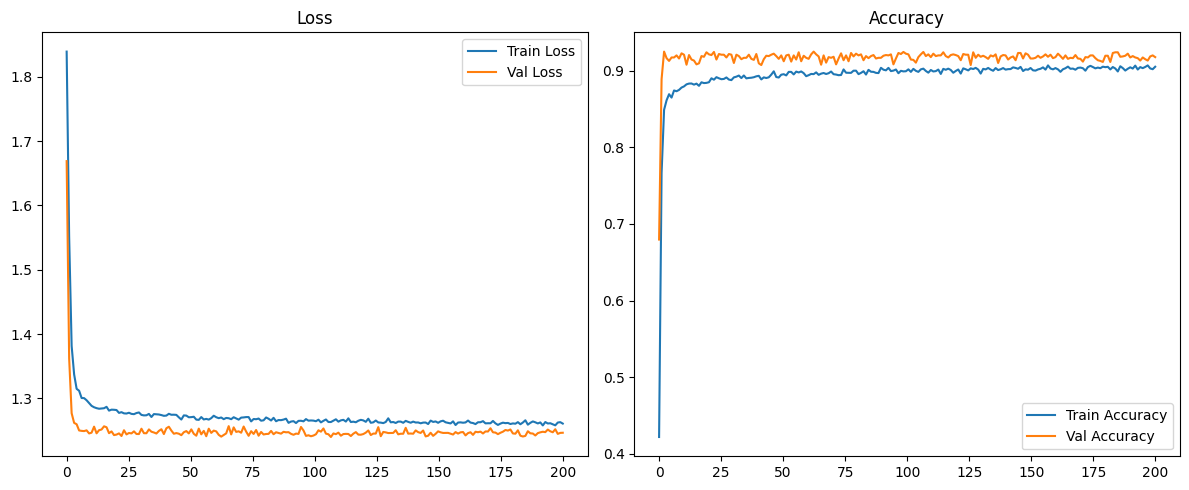

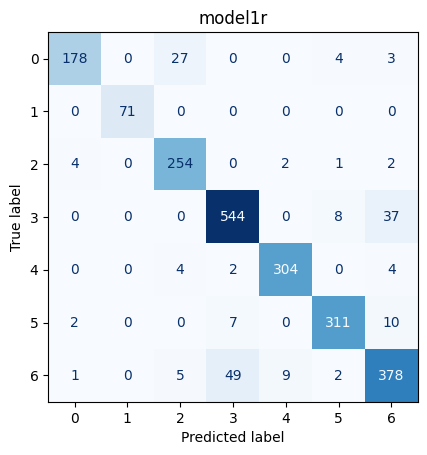

In [3]:
dataset_name = 'beans'
model_name = 'model1r'

dataset = ds.Dataset(dataset_name)
X_train, _, _ = dataset.train()
X_val, _, _ = dataset.validation()
X_test, _, _ = dataset.test()
print(X_train.shape, X_val.shape, X_test.shape)

results, acc_train, acc_val = eval_net(dataset_name, model_name, print_report = True, plot_acc = True, plot_conf = True)

# Accuracy comparison

In [4]:
dataset_list = ['adult', 'bank', 'beans', 'cancer', 'heloc', 'mushroom', 'ocean', 'wine']
models_list = ['model2', 'model2do1', 'model2bn', 'model2r']
models_colors = ['black', 'red', 'blue', 'green']

In [5]:
val = True # else the train accuracies are displayed

data = []
for dataset in dataset_list:
    row = [dataset]
    for model in models_list:
        history = joblib.load(f'./models/histories/{dataset}_{model}_history.joblib')
        if val:
            acc = history['val_acc'][-1]
        else:
            acc = history['train_acc'][-1]
        row.append(acc)
    data.append(row)

print('Validation accuracy\n' if val else 'Train accuracy\n')
print(tabulate(data, headers=["Dataset", *models_list], tablefmt="github", floatfmt=".4f"))

Validation accuracy

| Dataset   |   model2 |   model2do1 |   model2bn |   model2r |
|-----------|----------|-------------|------------|-----------|
| adult     |   0.8401 |      0.8360 |     0.8331 |    0.8363 |
| bank      |   0.9084 |      0.8825 |     0.9068 |    0.9085 |
| beans     |   0.9208 |      0.8898 |     0.9073 |    0.9199 |
| cancer    |   0.9669 |      0.9587 |     0.9835 |    0.9669 |
| heloc     |   0.6803 |      0.6859 |     0.6639 |    0.6903 |
| mushroom  |   1.0000 |      1.0000 |     1.0000 |    1.0000 |
| ocean     |   0.6826 |      0.6743 |     0.7894 |    0.7776 |
| wine      |   0.8295 |      0.8205 |     0.8218 |    0.8244 |


# ROC-AUC scores comparison

In [6]:
results = []
y_vals = []

for dataset in dataset_list:
    ddd = ds.Dataset(dataset)
    _, _, y_val = ddd.validation()
    y_vals.append(y_val)
    res = []
    for model in models_list:
        r = joblib.load(f'./models/results/{dataset}_{model}_results.joblib')
        res.append(r)
    results.append(res)

In [7]:
def ovr_roc(y_onehot, proba):
    if proba.shape[1] == 2:
        y, p = y_onehot[:, 1], proba[:, 1]
    else:
        y, p = y_onehot.ravel(), proba.ravel()
    fpr, tpr, _ = roc_curve(y, p)
    return roc_auc_score(y, p), fpr, tpr

def plot_roc(y_val, results, dataset_name, models_colors, models_list):
    y_onehot = y_val.detach().numpy()
    auc_scores = []

    plt.figure()
    plt.title(dataset_name)
    for i in range(len(results)):
        roc, fpr, tpr = ovr_roc(y_onehot, results[i]['pred_proba'][0])
        plt.plot(fpr, tpr, color=models_colors[i], label=f'{models_list[i]} - {roc:.4f}')
        auc_scores.append(roc)

    plt.plot([0,1],[0,1], color='grey', linestyle='--', label='Random')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.legend()

    plt.tight_layout()
    plt.show()

    return auc_scores

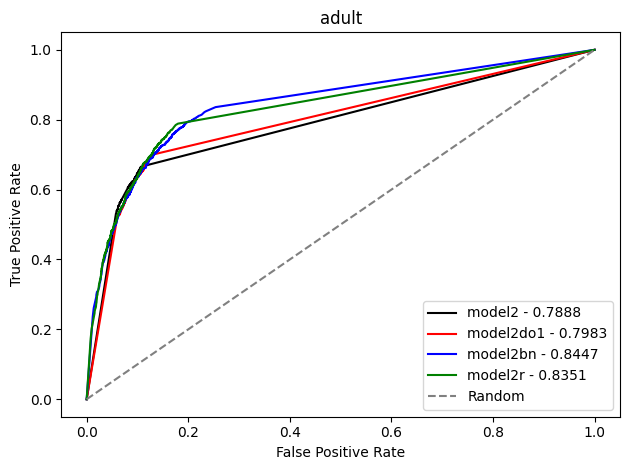

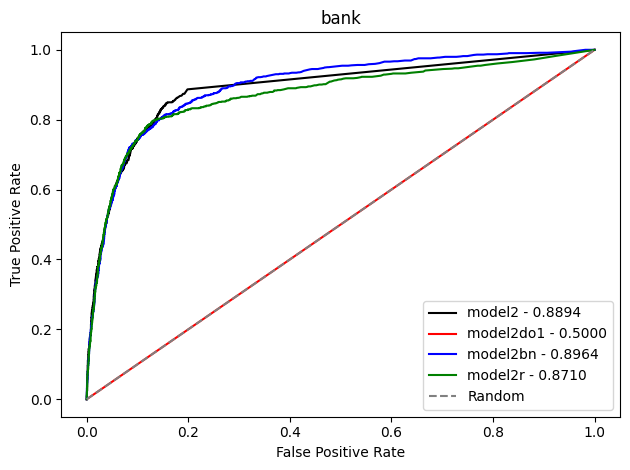

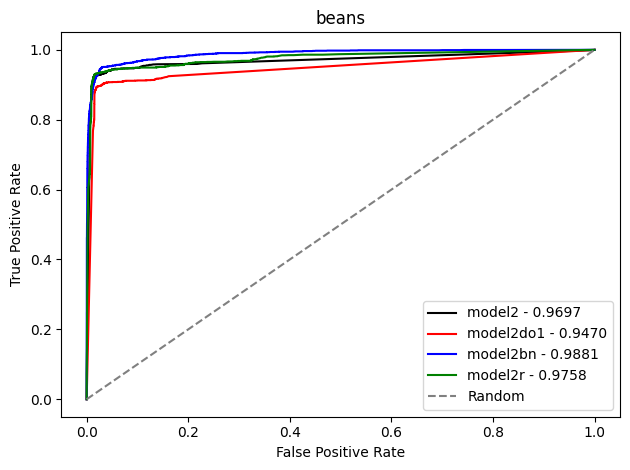

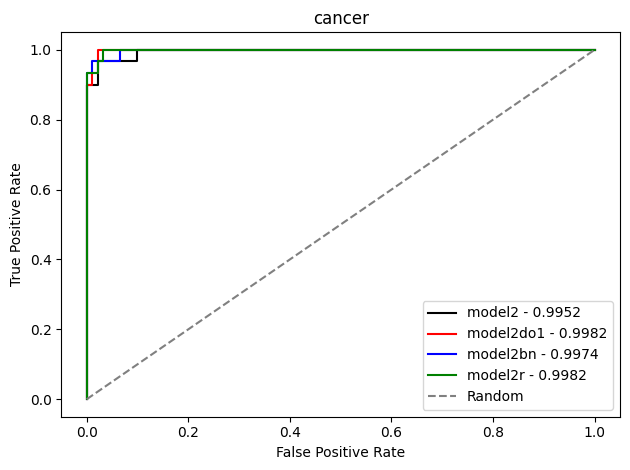

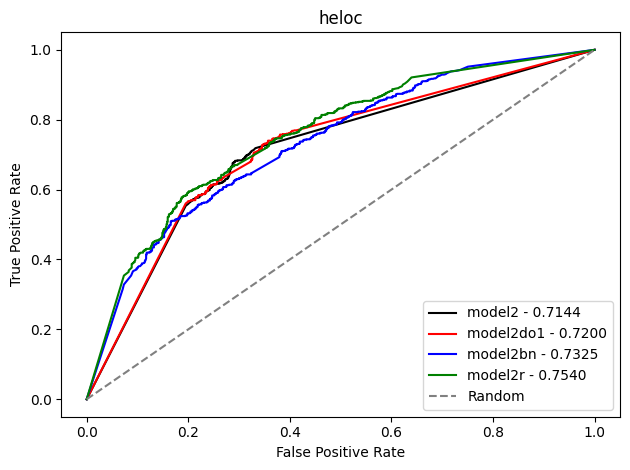

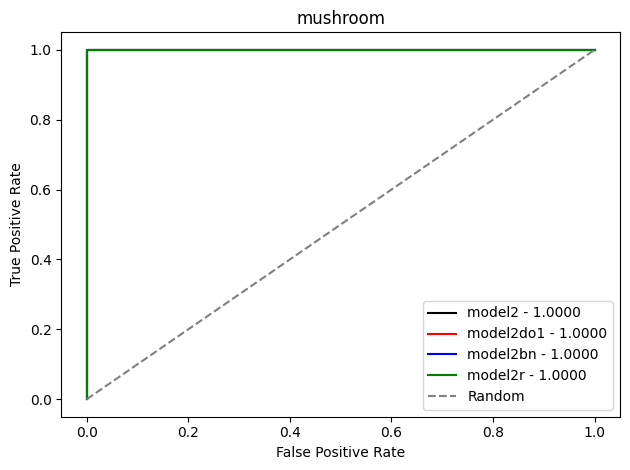

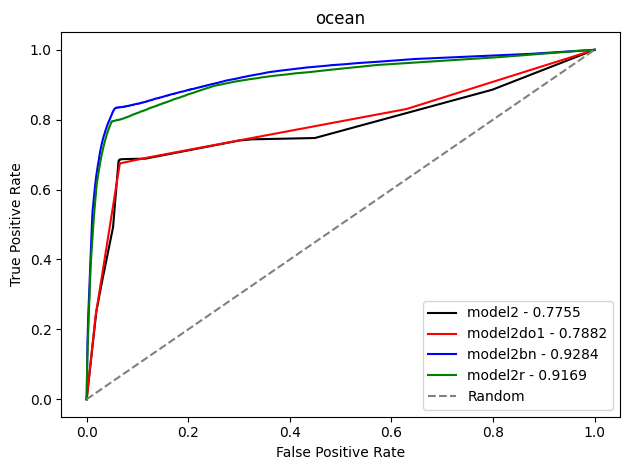

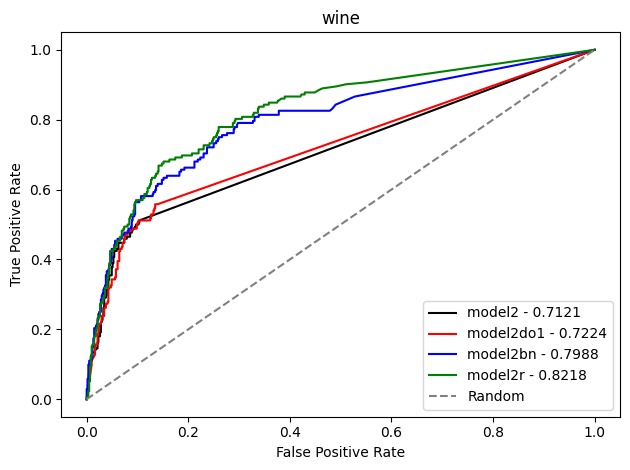

In [8]:
auc_scores = []
for idx, dataset in enumerate(dataset_list):
    auc = plot_roc(y_vals[idx], results[idx], dataset, models_colors, models_list)
    auc_scores.append(auc)

In [9]:
print("AUC score\n")
data = [[name, *scores] for name, scores in zip(dataset_list, auc_scores)]
headers = ["Dataset", *models_list]
print(tabulate(data, headers=headers, tablefmt="github", floatfmt=".4f"))

AUC score

| Dataset   |   model2 |   model2do1 |   model2bn |   model2r |
|-----------|----------|-------------|------------|-----------|
| adult     |   0.7888 |      0.7983 |     0.8447 |    0.8351 |
| bank      |   0.8894 |      0.5000 |     0.8964 |    0.8710 |
| beans     |   0.9697 |      0.9470 |     0.9881 |    0.9758 |
| cancer    |   0.9952 |      0.9982 |     0.9974 |    0.9982 |
| heloc     |   0.7144 |      0.7200 |     0.7325 |    0.7540 |
| mushroom  |   1.0000 |      1.0000 |     1.0000 |    1.0000 |
| ocean     |   0.7755 |      0.7882 |     0.9284 |    0.9169 |
| wine      |   0.7121 |      0.7224 |     0.7988 |    0.8218 |
